# 02 — Le moteur d'analyse sémantique et le mécanisme de scoring

Ce notebook explique et justifie le cœur du projet : comment des réponses en langage naturel deviennent des scores
de compétences, des scores de couverture par bloc et par métier, puis une recommandation expliquée
(exigences 3, 4 et 5 du sujet).

```
réponses ──1──► preuves (propositions) ──2──► embeddings SBERT ──► cosinus preuves × 71 compétences
                                                                         │ 3. calibration [0, 1]
                                                                         ▼
     score sémantique d'une compétence = meilleure preuve  ──4──►  + auto-évaluation (Likert)
                                                                         │
                       5. couverture par bloc et par métier (moyennes pondérées, formule du sujet)
                       6. affinité objectif ↔ métier          7. score final, top 3, explications
```

**Plan**

1. Pourquoi des embeddings de phrases contextuels ? (comparaison sur des exemples)
2. Le pipeline pas à pas sur un profil
3. Calibration de la similarité cosinus
4. Le problème de la négation
5. Récapitulatif des paramètres et de leur justification

In [1]:
# --- Mise en place : chemins, bibliothèques et style des graphiques ---
import sys, warnings, os
from pathlib import Path
warnings.filterwarnings("ignore")
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"

RACINE = Path.cwd().parent            # le notebook est dans notebooks/, le code dans src/
sys.path.insert(0, str(RACINE))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)

# Palette catégorielle (ordre fixe, validée pour le daltonisme) et couleurs d'encre
BLEU, ORANGE, AQUA, JAUNE, MAGENTA, VERT, VIOLET, ROUGE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                                         "#e87ba4", "#008300", "#6250d6", "#e34948"]
SERIES = [BLEU, ORANGE, AQUA, JAUNE, MAGENTA, VERT, VIOLET, ROUGE]
ENCRE, ENCRE_2, MUET, GRILLE, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "figure.dpi": 110,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "Arial", "DejaVu Sans"],
    "text.color": ENCRE, "axes.labelcolor": ENCRE_2, "xtick.color": MUET, "ytick.color": MUET,
    "axes.edgecolor": GRILLE, "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False,
})

In [2]:
from src import config
from src.referentiel import Referentiel
from src.embeddings import encodeur_sbert, EncodeurTFIDF, EncodeurMotsStatiques
from src.moteur import MoteurRecommandation, construire_preuves, calibrer
from src.preprocessing import est_negative
from src.evaluation import charger_personas

ref = Referentiel.charger()
sbert = encodeur_sbert()                                          # modèle principal
corpus = ref.competences["texte_embedding"].tolist() + ref.metiers["texte_embedding"].tolist()
tfidf = EncodeurTFIDF(corpus)                                     # comparaison lexicale
statique = EncodeurMotsStatiques()                                # comparaison : embeddings de mots
moteur = MoteurRecommandation(ref, sbert)
personas = {p["id"]: p for p in charger_personas()}
print("Modèle :", config.MODELE_SBERT, "| dimension :", sbert.modele.get_sentence_embedding_dimension())

Could not reach the Hub (Cannot reach https://huggingface.co/api/models/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2: offline mode is enabled. To disable it, please unset the `HF_HUB_OFFLINE` environment variable.). Using cached commit hash for 'sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2'.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Modèle : sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2 | dimension : 384


## 1. Pourquoi des embeddings de phrases contextuels ?

Le sujet demande une analyse qui aille « au-delà de la simple correspondance de mots-clés ». On compare trois
représentations sur des paires de phrases choisies pour piéger chacune d'elles :

| Représentation | Principe | Limite attendue |
|---|---|---|
| **TF-IDF** sur les lemmes | deux textes sont proches s'ils partagent des mots (rares) | aveugle aux synonymes et aux paraphrases |
| **Embeddings de mots** (fastText, moyenne) | chaque mot a un vecteur fixe ; une phrase est la moyenne de ses mots | un mot a le même vecteur quel que soit son contexte ; la moyenne dilue le sens |
| **SBERT** (`paraphrase-multilingual-MiniLM-L12-v2`) | un Transformer lit toute la phrase et produit un vecteur entraîné pour que deux paraphrases soient proches | plus coûteux ; sensible à la polarité (voir section 4) |

Le moteur pose toujours la même question : *parmi les 71 compétences, laquelle cette phrase décrit-elle, et avec
quelle force ?* On soumet donc à chaque méthode deux sortes de phrases :

- des **paraphrases** : elles décrivent une compétence sans reprendre son vocabulaire. On regarde le **rang** de la
  bonne compétence parmi les 71 (1 = trouvée en premier) ;
- des **pièges lexicaux** : elles partagent des mots avec une compétence (« nettoyer », « modèle »,
  « conteneurs ») mais parlent d'autre chose. Aucune compétence ne devrait ressortir : on regarde la compétence
  classée première et son cosinus.

In [3]:
encodeurs = {"TF-IDF": tfidf, "fastText (moyenne)": statique, "SBERT": sbert}
emb_comp = {nom: enc.encoder(ref.competences["texte_embedding"].tolist()) for nom, enc in encodeurs.items()}
ids, noms_comp = ref.ids_competences, ref.competences["competence"].tolist()

paraphrases = [
    ("Je remettais au propre des exports clients pleins de trous et de lignes en double.", "C19"),
    ("Mon outil devine si un avis client est content ou mécontent.", "C49"),
    ("J'ai estimé le prix des appartements à partir de leur surface et de leur quartier.", "C35"),
    ("J'empaquette l'application avec ses dépendances pour qu'elle tourne partout pareil.", "C54"),
    ("Je réunis les futurs utilisateurs pour comprendre ce dont ils ont réellement besoin.", "C63"),
]
pieges = ["Je nettoie les vitres et je prépare la vitrine du magasin chaque matin.",
          "J'ai construit un modèle réduit d'avion en bois avec mon fils.",
          "Je range mes affaires dans des conteneurs en plastique avant un déménagement."]

# Rang de la bonne compétence pour chaque paraphrase
rangs = pd.DataFrame({nom: [int(np.where(np.argsort(-(enc.encoder([p]) @ emb_comp[nom].T)[0]) == ids.index(c))[0][0]) + 1
                            for p, c in paraphrases] for nom, enc in encodeurs.items()},
                     index=[f"{p[:60]}… → {noms_comp[ids.index(c)]}" for p, c in paraphrases])
print("Rang de la bonne compétence parmi 71 (1 = trouvée en premier)")
display(rangs)

# Pour les pièges : compétence classée première et cosinus obtenu
lignes = []
for p in pieges:
    ligne = {"piège": p}
    for nom, enc in encodeurs.items():
        s = (enc.encoder([p]) @ emb_comp[nom].T)[0]
        ligne[nom] = f"{noms_comp[int(s.argmax())]} ({s.max():.2f})"
    lignes.append(ligne)
print("Pièges lexicaux : compétence classée première (cosinus)")
display(pd.DataFrame(lignes).set_index("piège"))

Rang de la bonne compétence parmi 71 (1 = trouvée en premier)


,TF-IDF,fastText (moyenne),SBERT
Je remettais au propre des exports clients pleins de trous e… → Nettoyage et préparation des données,19,1,17
Mon outil devine si un avis client est content ou mécontent.… → Classification de textes et analyse de sentiments,51,27,4
J'ai estimé le prix des appartements à partir de leur surfac… → Modèles de régression,39,2,4
J'empaquette l'application avec ses dépendances pour qu'elle… → Conteneurisation,2,11,22
Je réunis les futurs utilisateurs pour comprendre ce dont il… → Recueil et analyse des besoins,1,2,1


Pièges lexicaux : compétence classée première (cosinus)


,TF-IDF,fastText (moyenne),SBERT
piège,,,
Je nettoie les vitres et je prépare la vitrine du magasin chaque matin.,Nettoyage et préparation des données (0.30),Transformers et modèles de langage (0.36),Supervision et monitoring (0.22)
J'ai construit un modèle réduit d'avion en bois avec mon fils.,Modèles de régression (0.38),Transformers et modèles de langage (0.57),Transformers et modèles de langage (0.27)
Je range mes affaires dans des conteneurs en plastique avant un déménagement.,Conteneurisation (0.29),Nettoyage et préparation des données (0.76),Conteneurisation (0.27)


> **Interprétation.** Ces quelques exemples montrent pourquoi il faut regarder **deux** propriétés, et pas seulement le classement.
>
> 1. **Retrouver la bonne compétence (paraphrases).** Aucune méthode n'est parfaite sur ces 5 phrases. TF-IDF échoue dès qu'il n'y a pas de mot commun : « devine si un avis est content » arrive au rang 51 pour *Classification de textes et analyse de sentiments*. fastText s'en sort bien ici, et SBERT place 3 phrases sur 5 dans ses 4 premières compétences. Quelques exemples ne suffisent pas à départager les méthodes : le notebook 03 les compare sur 40 paraphrases et 25 profils complets.
> 2. **Ne rien trouver quand il n'y a rien (pièges).** C'est là que les méthodes se séparent nettement. TF-IDF classe premier *exactement* la compétence qui partage le mot piège (« nettoie » → Nettoyage des données, « modèle » → Modèles de régression, « conteneurs » → Conteneurisation). fastText donne des cosinus élevés à tout : la phrase sur les conteneurs en plastique obtient 0,76 avec *Nettoyage et préparation des données*, plus que beaucoup de vraies correspondances. Avec une telle échelle, impossible de fixer un seuil « cette phrase ne démontre rien ». SBERT, lui, ne dépasse jamais 0,27 sur les pièges : tous restent sous le seuil de bruit COS_BAS = 0,35 et la calibration les ramène à 0.
>
> **Pour notre moteur, la deuxième propriété est essentielle.** Le score d'une compétence est le *maximum* sur toutes les phrases de l'utilisateur : une seule fausse correspondance forte suffit à inventer une compétence. Il faut donc une représentation dont le cosinus a un **sens absolu**, et c'est ce qu'apporte un modèle entraîné sur des paires de paraphrases.

## 2. Le pipeline pas à pas sur un profil

On suit le persona **P03**, un ingénieur de l'équipe data d'un assureur (métier attendu : Data Scientist).

### Étape 1 — Des réponses aux preuves

In [4]:
p = personas["P03"]
for k, v in p["reponses"]["textes"].items():
    print(f"[{k}] {v}\n")
preuves, negatives, lacunes = construire_preuves(p["reponses"], ref)
display(pd.DataFrame([{"preuve": x.texte, "source": x.source, "type": x.type, "poids": x.poids} for x in preuves]))
print("Phrases négatives écartées :", negatives)
print("Lacunes déclarées :", lacunes)

[parcours] Ingénieur diplômé avec une spécialisation en intelligence artificielle, je travaille depuis deux ans dans l'équipe data d'un assureur.

[projet] J'ai construit un modèle qui estime la probabilité qu'un client parte à la concurrence. J'ai préparé les variables à partir de l'historique des contrats, comparé plusieurs algorithmes comme les forêts aléatoires et le gradient boosting, et choisi le meilleur avec une validation croisée sur l'AUC.

[taches] J'aime formuler un problème métier comme un problème de prédiction. Je suis à l'aise avec les probabilités et les tests d'hypothèses.



,preuve,source,type,poids
0,"Ingénieur diplômé avec une spécialisation en intelligence artificielle, je travaille d...",Parcours,texte,1.00
1,J'ai construit un modèle qui estime la probabilité qu'un client parte à la concurrence,Projet,texte,1.00
2,"J'ai préparé les variables à partir de l'historique des contrats, comparé plusieurs al...",Projet,texte,1.00
3,J'aime formuler un problème métier comme un problème de prédiction,Tâches préférées,texte,1.00
4,Je suis à l'aise avec les probabilités et les tests d'hypothèses,Tâches préférées,texte,1.00
5,J'ai déjà nettoyé et préparé un jeu de données réel avant de l'analyser.,Question guidée G1 (oui),guidee_oui,0.70
6,J'ai entraîné un modèle de churn et suivi son rappel sur les clients à risque,Question guidée G2,texte,1.00
7,J'écris des programmes et des scripts en Python.,Outil coché : Python,outil,0.85
8,Je manipule et nettoie des tableaux de données avec pandas et NumPy.,Outil coché : pandas / NumPy,outil,0.85
9,J'entraîne et j'évalue des modèles de machine learning avec scikit-learn.,Outil coché : scikit-learn,outil,0.85


Phrases négatives écartées : []
Lacunes déclarées : ["Pas d'expérience déclarée en déploiement en production."]


> **Interprétation.** Les réponses de P03 donnent 12 preuves de poids différents : 6 propositions rédigées (poids 1,0, dont la précision donnée à la question guidée G2), 1 « oui » sans précision (G1, poids 0,7) et 5 outils cochés (poids 0,85). Le découpage sépare bien les deux phrases du projet : la première parle de la cible du modèle (le départ des clients), la seconde de la méthode (préparation des variables, comparaison d'algorithmes, validation croisée). Elles pourront donc être rapprochées de compétences différentes. Le « non » à la question sur la mise en production est noté comme lacune, sans être une preuve.

### Étapes 2 et 3 — Embeddings, matrice de similarité et calibration

Chaque preuve et chaque compétence (« libellé : description ») devient un vecteur de 384 dimensions de norme 1.
La similarité cosinus est alors un simple produit scalaire : on obtient une matrice *preuves × 71 compétences*.

Matrice de similarité : (12, 71) (preuves × compétences)


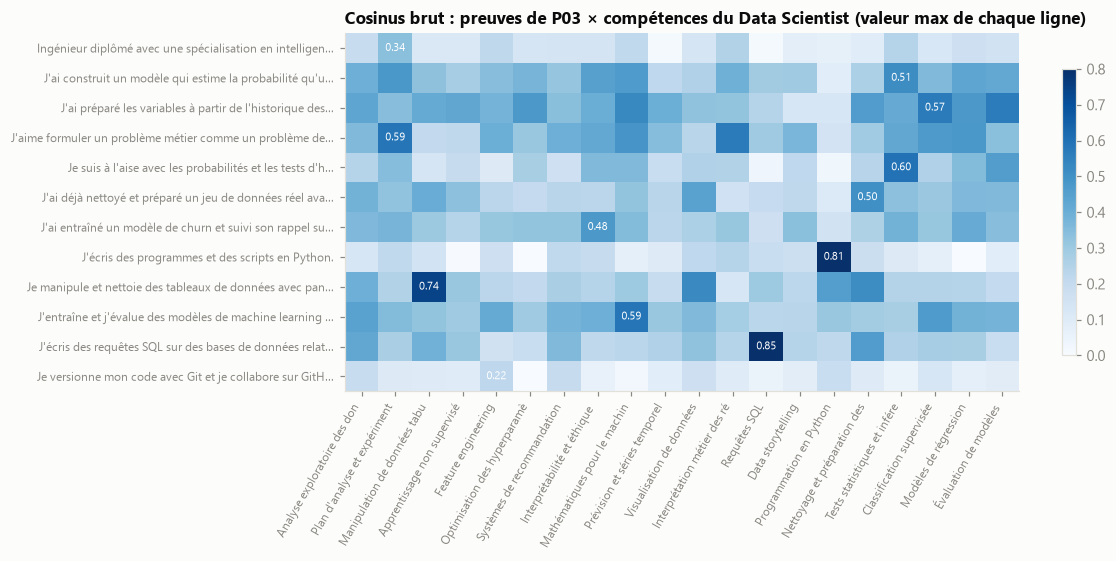

In [5]:
res = moteur.analyser(p["reponses"])
print("Matrice de similarité :", res.cosinus.shape, "(preuves × compétences)")

# Zoom sur les compétences cœur et secondaires du Data Scientist
poids_ds = ref.poids_metier("J02")
idx = [ref.ids_competences.index(c) for c in poids_ds]
noms = ref.competences.loc[idx, "competence"].tolist()
fig, ax = plt.subplots(figsize=(11, 5.2))
im = ax.imshow(res.cosinus[:, idx], cmap="Blues", vmin=0, vmax=0.8, aspect="auto")
ax.set_xticks(range(len(idx)), [n[:28] for n in noms], rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(res.preuves)), [x.texte[:55] + ("…" if len(x.texte) > 55 else "") for x in res.preuves], fontsize=8)
for i in range(len(res.preuves)):
    j = int(np.argmax(res.cosinus[i, idx]))
    ax.text(j, i, f"{res.cosinus[i, idx][j]:.2f}", ha="center", va="center", fontsize=7, color="white")
ax.grid(False); ax.set_title("Cosinus brut : preuves de P03 × compétences du Data Scientist (valeur max de chaque ligne)")
plt.colorbar(im, ax=ax, shrink=0.8); plt.tight_layout(); plt.show()

> **Interprétation.** Chaque ligne montre une preuve et sa similarité avec chacune des 20 compétences du Data Scientist ; la valeur écrite est le maximum de la ligne. Les phrases rédigées par l'utilisateur se rapprochent des compétences qu'elles décrivent sans les nommer : « je suis à l'aise avec les probabilités et les tests d'hypothèses » rejoint *Tests statistiques et inférence*, la phrase sur la comparaison d'algorithmes rejoint *Classification supervisée* et *Évaluation de modèles*. La phrase de parcours (« ingénieur diplômé… équipe data d'un assureur ») reste pâle partout : elle situe le profil sans décrire de compétence, et l'agrégation par maximum fait qu'elle ne pénalise rien.

### Étape 4 — Score de chaque compétence

$$
\text{sem}_c = \max_{p \in \text{preuves}} \; w_p \cdot \text{calib}\big(\cos(p, c)\big)
\qquad\qquad
s_c = \alpha \cdot \text{sem}_c + (1-\alpha)\cdot \frac{L_{\text{bloc}(c)} - 1}{4}
$$

- **Le maximum, pas la moyenne** : une compétence est démontrée dès qu'*une* phrase la décrit bien. Une phrase
  hors sujet (« je suis motivé ») ne fait baisser aucun score. Le pseudocode du sujet fait l'inverse (moyenne
  sur les phrases du meilleur score dans le bloc) : une réponse riche en sujets variés y est pénalisée.
  L'effet est mesuré dans le notebook 03.
- $w_p$ : poids de la preuve (texte rédigé 1,0 ; outil coché 0,85 ; « oui » sans précision 0,7). Une phrase
  écrite par l'utilisateur décrit un contexte d'usage réel, une case cochée seulement une familiarité.
- $\alpha = 0{,}75$ : l'auto-évaluation (Likert) complète l'analyse des textes sans la dominer.

In [6]:
cols = ["competence", "bloc_id", "semantique", "auto_evaluation", "score", "statut", "meilleure_preuve", "cosinus_brut"]
display(res.competences.sort_values("score", ascending=False)[cols].head(12).round(2))

,competence,bloc_id,semantique,auto_evaluation,score,statut,meilleure_preuve,cosinus_brut
0,Programmation en Python,B1,0.85,0.75,0.82,maîtrisée,J'écris des programmes et des scripts en Python.,0.81
3,Gestion de versions et revue de code,B1,0.85,0.75,0.82,maîtrisée,Je versionne mon code avec Git et je collabore sur GitHub.,0.77
23,Manipulation de données tabulaires,B3,0.85,0.75,0.82,maîtrisée,Je manipule et nettoie des tableaux de données avec pandas et NumPy.,0.74
21,Tests statistiques et inférence,B3,0.82,0.75,0.80,maîtrisée,Je suis à l'aise avec les probabilités et les tests d'hypothèses,0.60
33,Classification supervisée,B5,0.73,1.00,0.80,maîtrisée,"J'ai préparé les variables à partir de l'historique des contrats, comparé plusieurs al...",0.57
37,Évaluation de modèles,B5,0.71,1.00,0.78,maîtrisée,"J'ai préparé les variables à partir de l'historique des contrats, comparé plusieurs al...",0.56
6,Automatisation par scripts,B1,0.79,0.75,0.78,maîtrisée,J'écris des programmes et des scripts en Python.,0.63
22,Plan d'analyse et expérimentation,B3,0.79,0.75,0.78,maîtrisée,J'aime formuler un problème métier comme un problème de prédiction,0.59
10,Modélisation de bases de données,B2,0.85,0.50,0.76,maîtrisée,J'écris des requêtes SQL sur des bases de données relationnelles.,0.65
9,Requêtes SQL,B2,0.85,0.50,0.76,maîtrisée,J'écris des requêtes SQL sur des bases de données relationnelles.,0.85


### Étape 5 — Couverture par bloc et par métier (formule du sujet)

Pour un métier $j$, on regroupe ses compétences requises par bloc $i$ :
$W_{ij}$ = somme des poids (cœur = 2, secondaire = 1) et $S_{ij}$ = moyenne pondérée des scores. Alors

$$
\text{Couverture}_j = \frac{\sum_i W_{ij}\, S_{ij}}{\sum_i W_{ij}}
$$

C'est la formule $\sum W_i S_i / \sum W_i$ du sujet, avec des poids $W_i$ qui ne sont pas fixés à 1 : ils viennent
de la composition du métier. Un bloc qui contient 4 compétences cœur du métier compte plus qu'un bloc qui n'en
contient qu'une compétence secondaire.

In [7]:
tableau = moteur.couverture_par_bloc("J02", res.competences)
tableau["W·S"] = tableau["W"] * tableau["S"]
display(tableau.round(3))
calcul = tableau["W·S"].sum() / tableau["W"].sum()
print(f"Couverture Data Scientist = {tableau['W·S'].sum():.3f} / {tableau['W'].sum():.0f} = {calcul:.3f}")
print(f"Valeur calculée par le moteur : {res.metiers.set_index('metier_id').at['J02', 'couverture']:.3f}")

,bloc_id,bloc,W,S,W·S
0,B1,Programmation et génie logiciel,2.0,0.825,1.650
1,B2,Bases de données et ingénierie des données,1.0,0.762,0.762
2,B3,Analyse de données et statistiques,9.0,0.634,5.708
3,B4,Visualisation et informatique décisionnelle,2.0,0.335,0.670
4,B5,Machine learning et modélisation,12.0,0.614,7.374


Couverture Data Scientist = 16.164 / 26 = 0.622
Valeur calculée par le moteur : 0.622


### Étapes 6 et 7 — Affinité avec l'objectif, score final et classement

L'objectif professionnel (« *Concevoir des modèles prédictifs qui aident l'entreprise à anticiper le comportement
de ses clients* ») est comparé aux phrases qui décrivent chaque métier : intitulé, phrases de la définition ROME et
descriptions de ses compétences cœur. On garde le meilleur appariement.

$$
\text{Score}_j = \beta \cdot \text{Couverture}_j + (1 - \beta)\cdot \text{Affinité}_j \qquad \beta = 0{,}9
$$

In [8]:
print("Objectif :", res.objectif, "\n")
display(res.metiers.round(3))

Objectif : Concevoir des modèles prédictifs qui aident l'entreprise à anticiper le comportement de ses clients. 



,metier_id,metier,code_rome,couverture,affinite,score,rang
0,J02,Data Scientist,M1405,0.622,0.788,0.638,1
1,J01,Data Analyst,M1419,0.517,0.764,0.542,2
2,J04,Ingénieur Machine Learning,M1889,0.529,0.602,0.536,3
3,J11,Architecte base de données,M1868,0.455,0.615,0.471,4
4,J10,Développeur logiciel,M1861,0.502,0.093,0.461,5
5,J08,Analyste décisionnel BI,M1851,0.363,0.917,0.419,6
6,J03,Data Engineer,M1811,0.462,0.026,0.418,7
7,J06,Ingénieur MLOps,M1889,0.402,0.502,0.412,8
8,J07,Développeur BI,M1824,0.379,0.458,0.387,9
9,J12,Product Owner Data / IA,M1864,0.269,0.806,0.323,10


In [9]:
for r in res.recommandations:
    print(f"{r['rang']}. {r['metier']} — score {r['score']:.0%} (couverture {r['couverture']:.0%}, affinité {r['affinite']:.0%})")
    print("   Critères :", "; ".join(f"{c['competence']} ({c['score']:.0%})" for c in r["criteres"]))
    print("   Explication :", r["explication"], "\n")
print("SYNTHÈSE DU PROFIL :", res.synthese)

1. Data Scientist — score 64% (couverture 62%, affinité 79%)
   Critères : Programmation en Python (82%); Tests statistiques et inférence (80%); Classification supervisée (80%)
   Explication : Ce métier s'appuie sur vos acquis en machine learning et modélisation et analyse de données et statistiques. Votre réponse « Je suis à l'aise avec les probabilités et les tests d'hypothèses » (tâches préférées) a été rapprochée de la compétence « Tests statistiques et inférence » (similarité cosinus 0.60). Il correspond aussi au type de poste que vous décrivez dans votre objectif. Toutes les compétences clés de ce métier apparaissent au moins partiellement dans vos réponses. 

2. Data Analyst — score 54% (couverture 52%, affinité 76%)
   Critères : Manipulation de données tabulaires (82%); Requêtes SQL (76%); Nettoyage et préparation des données (54%)
   Explication : Ce métier s'appuie sur vos acquis en analyse de données et statistiques et bases de données et ingénierie des données. Votre répo

> **Interprétation.**
>
> - **La formule du sujet est vérifiée à la main.** Couverture Data Scientist = 16,164 / 26 = 0,622, exactement la valeur du moteur. Les blocs B5 (W = 12) et B3 (W = 9) pèsent le plus, car ils contiennent la majorité des compétences du métier. Le bloc B4 (visualisation, S = 0,335) fait baisser la couverture : P03 ne parle jamais de graphiques ni de présentation de résultats.
> - **Le bon métier arrive en tête** (Data Scientist, 64 %), devant Data Analyst (54 %) et Ingénieur Machine Learning (54 %) : ce sont bien les deux métiers voisins.
> - **Pourquoi l'affinité ne pèse que 10 %.** L'affinité seule aurait classé l'Analyste décisionnel premier (0,917 contre 0,788) et placé le Product Owner haut (0,806). Une phrase d'objectif comme « aider l'entreprise à anticiper » ressemble à beaucoup de descriptions de métiers. Elle est utile pour départager, pas pour décider : c'est le rôle de β = 0,9.
> - **L'explication est entièrement dérivée des résultats** : les blocs qui contribuent le plus (W·S), une citation de l'utilisateur avec son cosinus, l'affinité et les compétences cœur manquantes, le tout assemblé par des modèles de phrases. Aucun modèle génératif n'intervient.
> - **Niveau** : la couverture de 62 % du métier recommandé tombe entre 50 et 70 %, d'où un « profil intermédiaire ». C'est cohérent pour un ingénieur avec deux ans d'expérience qui n'a jamais mis de modèle en production.

## 3. Calibration de la similarité cosinus

Un cosinus SBERT brut n'est pas directement interprétable. Deux phrases sans rapport ont souvent un cosinus de
0,2 à 0,3, et une paraphrase nette dépasse rarement 0,8. On le ramène sur [0, 1] par une transformation
linéaire bornée :

$$
\text{calib}(\cos) = \text{clip}\left(\frac{\cos - \text{COS\_BAS}}{\text{COS\_HAUT} - \text{COS\_BAS}},\ 0,\ 1\right)
$$

Les deux bornes sont **mesurées** sur les 25 personas de test :

- **COS_BAS** : comme le score d'une compétence est le *maximum* sur une quinzaine de preuves, le bruit à
  neutraliser est la meilleure similarité obtenue pour une compétence **absente** du profil (une compétence d'un
  bloc que le persona a noté 1/5), pas la similarité d'une paire quelconque ;
- **COS_HAUT** : la meilleure similarité obtenue pour les compétences **cœur du bon métier**.

,count,25%,50%,75%,90%
paire quelconque,17679.0,0.162,0.240,0.319,0.395
"meilleure preuve, compétence absente",640.0,0.303,0.352,0.414,0.474
"meilleure preuve, compétence cœur du bon métier",130.0,0.515,0.596,0.720,0.844


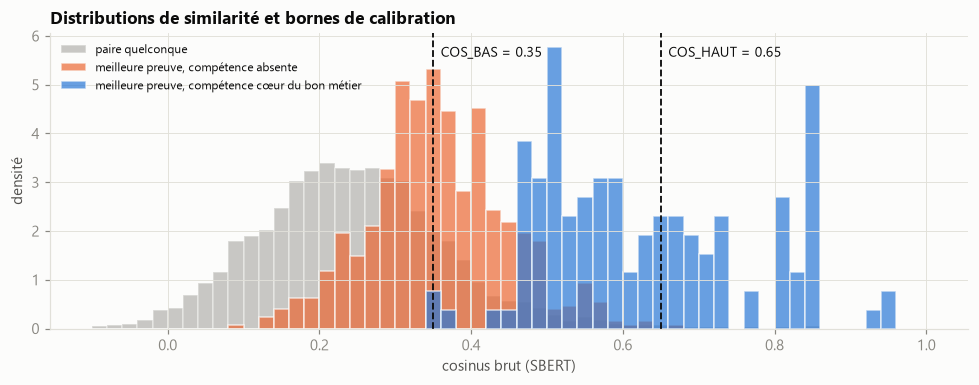

In [10]:
toutes, absentes, presentes = [], [], []
for pp in personas.values():
    pr, _, _ = construire_preuves(pp["reponses"], ref)
    C = sbert.encoder([x.texte for x in pr]) @ moteur.emb_competences.T
    toutes.append(C.ravel())
    poids = ref.poids_metier(pp["metier_attendu"])
    coeur = [i for i, c in enumerate(ref.ids_competences) if poids.get(c) == config.POIDS_COEUR]
    absent = [i for i, b in enumerate(ref.competences["bloc_id"]) if pp["reponses"]["likert"].get(b) == 1]
    presentes += list(C[:, coeur].max(axis=0))
    absentes += list(C[:, absent].max(axis=0))
toutes = np.concatenate(toutes)

stats = pd.DataFrame({
    "paire quelconque": pd.Series(toutes).describe(percentiles=[.25, .5, .75, .9]),
    "meilleure preuve, compétence absente": pd.Series(absentes).describe(percentiles=[.25, .5, .75, .9]),
    "meilleure preuve, compétence cœur du bon métier": pd.Series(presentes).describe(percentiles=[.25, .5, .75, .9]),
}).T
display(stats[["count", "25%", "50%", "75%", "90%"]].round(3))

fig, ax = plt.subplots(figsize=(9, 3.6))
bins = np.linspace(-0.1, 1, 56)
ax.hist(toutes, bins=bins, density=True, color=MUET, alpha=0.45, label="paire quelconque", edgecolor=SURFACE)
ax.hist(absentes, bins=bins, density=True, color=ORANGE, alpha=0.7, label="meilleure preuve, compétence absente", edgecolor=SURFACE)
ax.hist(presentes, bins=bins, density=True, color=BLEU, alpha=0.7, label="meilleure preuve, compétence cœur du bon métier", edgecolor=SURFACE)
for x, t in [(config.COS_BAS, "COS_BAS"), (config.COS_HAUT, "COS_HAUT")]:
    ax.axvline(x, color=ENCRE, lw=1.2, ls="--"); ax.text(x + 0.01, ax.get_ylim()[1] * 0.92, f"{t} = {x}", fontsize=9)
ax.set_xlabel("cosinus brut (SBERT)"); ax.set_ylabel("densité"); ax.legend(loc="upper left", fontsize=8)
ax.set_title("Distributions de similarité et bornes de calibration"); plt.tight_layout(); plt.show()

> **Interprétation.** Les trois distributions sont bien séparées, ce qui justifie les deux bornes.
>
> - Une paire (phrase, compétence) quelconque a un cosinus médian de 0,24. Mais la meilleure preuve pour une compétence **absente** du profil atteint une médiane de 0,35 (75e centile 0,41), simplement parce qu'on prend un maximum sur une quinzaine de phrases. Si on avait calibré sur 0,24, chaque profil aurait reçu un score non nul sur presque toutes les compétences.
> - Pour les compétences **cœur du bon métier**, la meilleure preuve a une médiane de 0,60 et un 75e centile de 0,72.
> - Avec COS_BAS = 0,35 et COS_HAUT = 0,65, la moitié des compétences absentes reçoit exactement 0, et une compétence cœur typique reçoit environ 0,8. Les deux distributions se chevauchent entre 0,45 et 0,55 : ces cas reçoivent un score **partiel**, ce qui reflète bien une incertitude réelle.
>
> Ces bornes sont propres au modèle : un autre modèle d'embeddings a une autre échelle de cosinus, et il faut refaire la mesure (c'est ce que fait le notebook 03 pour chaque méthode comparée).

## 4. Le problème de la négation

Une phrase comme « *je n'ai jamais fait de NLP* » parle de NLP. Si le moteur la rapproche de la compétence NLP, il
augmente le score de ce que l'utilisateur dit justement **ne pas** savoir faire. On mesure le problème sur
8 paires de phrases (affirmative / négative) et sur la compétence qu'elles évoquent, pour chaque méthode.

In [11]:
paires_neg = [
    ("J'ai affiné des modèles BERT pour classer des documents.", "Je n'ai jamais affiné de modèles BERT pour classer des documents.", "C48"),
    ("J'ai déployé des applications sur AWS.", "Je n'ai jamais déployé d'application sur AWS.", "C53"),
    ("Je maîtrise Docker et Kubernetes.", "Je ne maîtrise ni Docker ni Kubernetes.", "C54"),
    ("J'ai construit des tableaux de bord sous Power BI.", "Je n'ai jamais construit de tableau de bord.", "C28"),
    ("J'ai entraîné des réseaux de neurones avec PyTorch.", "Je n'ai aucune expérience avec les réseaux de neurones.", "C43"),
    ("J'écris des requêtes SQL tous les jours.", "Je ne sais pas écrire de requêtes SQL.", "C10"),
    ("J'ai mis en place une intégration continue.", "Je n'ai pas encore mis en place d'intégration continue.", "C55"),
    ("J'ai fait des tests statistiques.", "Je n'ai jamais fait de tests statistiques.", "C22"),
]
lignes = []
for aff, neg, cid in paires_neg:
    j = ids.index(cid)
    ligne = {"phrase négative": neg, "détectée par la règle": est_negative(neg)}
    for nom, enc in encodeurs.items():
        a, n = (enc.encoder([aff, neg]) @ emb_comp[nom][j:j + 1].T)[:, 0]
        ligne[f"{nom} affirm."], ligne[f"{nom} nég."] = a, n
    lignes.append(ligne)
neg_df = pd.DataFrame(lignes)
display(neg_df.round(2))
for nom in encodeurs:
    a, n = neg_df[f"{nom} affirm."].mean(), neg_df[f"{nom} nég."].mean()
    print(f"{nom:20} cosinus moyen : affirmative {a:.2f} → négative {n:.2f}  ({(n - a) / a:+.0%})")
print(f"\nPhrases négatives SBERT encore au-dessus de COS_BAS = {config.COS_BAS} (elles compteraient comme preuves) :",
      int((neg_df['SBERT nég.'] > config.COS_BAS).sum()), "sur", len(neg_df))

,phrase négative,détectée par la règle,TF-IDF affirm.,TF-IDF nég.,fastText (moyenne) affirm.,fastText (moyenne) nég.,SBERT affirm.,SBERT nég.
0,Je n'ai jamais affiné de modèles BERT pour classer des documents.,True,0.32,0.32,0.80,0.81,0.44,0.15
1,Je n'ai jamais déployé d'application sur AWS.,True,0.27,0.27,0.66,0.54,0.40,0.29
2,Je ne maîtrise ni Docker ni Kubernetes.,True,0.40,0.40,0.69,0.69,0.71,0.38
3,Je n'ai jamais construit de tableau de bord.,True,0.48,0.65,0.57,0.75,0.35,0.02
4,Je n'ai aucune expérience avec les réseaux de neurones.,True,0.71,0.54,0.93,0.86,0.82,0.61
5,Je ne sais pas écrire de requêtes SQL.,True,0.58,0.64,0.71,0.78,0.63,0.63
6,Je n'ai pas encore mis en place d'intégration continue.,True,0.28,0.28,0.72,0.72,0.63,0.39
7,Je n'ai jamais fait de tests statistiques.,True,0.57,0.57,0.87,0.85,0.71,0.32


TF-IDF               cosinus moyen : affirmative 0.45 → négative 0.46  (+2%)
fastText (moyenne)   cosinus moyen : affirmative 0.74 → négative 0.75  (+1%)
SBERT                cosinus moyen : affirmative 0.59 → négative 0.35  (-41%)

Phrases négatives SBERT encore au-dessus de COS_BAS = 0.35 (elles compteraient comme preuves) : 4 sur 8


In [12]:
# Effet du traitement sur le persona P25 (« je n'ai jamais fait de deep learning ni de traitement du langage
# naturel », « je n'ai aucune expérience en mise en production ou en cloud »)
p25 = personas["P25"]["reponses"]
avec = MoteurRecommandation(ref, sbert).analyser(p25)
sans = MoteurRecommandation(ref, sbert, utiliser_negation=False).analyser(p25)
print("Phrases écartées :", [t for t, _ in avec.phrases_negatives])
blocs_cmp = pd.DataFrame({"bloc": avec.blocs["bloc"], "sémantique (top 3) SANS filtre": sans.blocs["semantique_top3"],
                          "sémantique (top 3) AVEC filtre": avec.blocs["semantique_top3"]})
display(blocs_cmp.round(3))
print("Top 3 sans filtre :", sans.metiers["metier"].head(3).tolist())
print("Top 3 avec filtre :", avec.metiers["metier"].head(3).tolist())

Phrases écartées : ["Je n'ai jamais fait de deep learning ni de traitement du langage naturel", "je n'ai aucune expérience en mise en production ou en cloud"]


,bloc,sémantique (top 3) SANS filtre,sémantique (top 3) AVEC filtre
0,Programmation et génie logiciel,0.000,0.000
1,Bases de données et ingénierie des données,0.832,0.832
2,Analyse de données et statistiques,0.476,0.476
3,Visualisation et informatique décisionnelle,0.726,0.726
4,Machine learning et modélisation,0.155,0.155
5,"Deep learning, NLP et IA générative",0.272,0.272
6,"Cloud, DevOps et MLOps",0.232,0.232
7,Gestion de projet et compétences transverses,0.401,0.401


Top 3 sans filtre : ['Développeur BI', 'Data Analyst', 'Architecte base de données']
Top 3 avec filtre : ['Développeur BI', 'Data Analyst', 'Architecte base de données']


> **Interprétation.** Le résultat est plus nuancé que l'idée reçue « les embeddings ne comprennent pas la négation », et il éclaire le choix du modèle.
>
> - **TF-IDF et fastText sont totalement aveugles à la négation** : le cosinus moyen ne bouge pas (+2 % et +1 %). Pour eux, « jamais » n'est qu'un mot de plus, voire un mot vide supprimé.
> - **SBERT y est sensible** : le cosinus moyen baisse de 41 % (0,59 → 0,35). Pour P25, les deux phrases négatives tombent ainsi sous le seuil de bruit : avec ou sans filtre, les scores et le top 3 sont identiques.
> - **Mais SBERT ne suffit pas toujours** : 4 phrases négatives sur 8 restent au-dessus de COS_BAS. Par exemple, « je ne sais pas écrire de requêtes SQL » garde 0,63 avec *Requêtes SQL*, autant que la phrase affirmative. Sans traitement, elles compteraient comme des preuves.
>
> **D'où notre approche en deux temps** : SBERT élimine déjà une bonne partie du problème, et une détection par règles (« ne… pas / jamais / aucun / ni », « sans expérience », « pas encore »…) écarte les phrases négatives restantes. Cette expérience a d'ailleurs révélé un oubli dans nos règles : « je **ne** maîtrise **ni** Docker **ni** Kubernetes » n'était pas détectée. Nous avons ajouté « ni » et un test unitaire, et les 8 phrases sont maintenant détectées. Les règles ont leurs limites (ironie, négations implicites comme « j'ai évité le cloud ») : c'est une limite connue du projet. Elle rejoint celle du TP3, où le modèle LSTM ne comprenait pas la négation.

## 5. Récapitulatif des paramètres

| Paramètre | Valeur | Justification |
|---|---|---|
| Modèle | `paraphrase-multilingual-MiniLM-L12-v2` | multilingue (français), entraîné sur des paraphrases, léger (≈ 470 Mo, CPU) ; meilleur sur le texte libre seul, à un persona du meilleur sur le système complet, 2,5 fois plus léger que mpnet (notebook 03) |
| Texte d'une compétence | libellé + description | une description « comme une expérience vécue » se rapproche de la façon dont l'utilisateur écrit |
| Unité d'analyse | proposition | une réponse longue mélange plusieurs compétences ; découper permet un appariement précis |
| Agrégation | max sur les preuves | une compétence est démontrée par une bonne phrase ; les phrases hors sujet ne pénalisent pas |
| COS_BAS, COS_HAUT | 0,35 ; 0,65 | mesurés (section 3) |
| Poids des preuves | 1,0 / 0,85 / 0,7 | texte rédigé > outil coché > « oui » sans précision |
| α (sémantique vs Likert) | 0,75 | l'analyse des textes domine, l'auto-évaluation complète |
| Poids cœur / secondaire | 2 / 1 | une compétence cœur pèse deux fois plus dans la couverture |
| β (couverture vs affinité) | 0,9 | l'objectif départage, il ne décide pas seul (mesuré dans le notebook 03) |
| Seuils de niveau | 0,7 / 0,5 | repris du sujet |
| Négation | règles | écarte les preuves qui affirment une absence de compétence |